**Name:** Rachel Sara Mathew  |  **Sec:** G  |  **SRN:** PES2UG24CS390


# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [ ]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 16 / 8 / 1024**2

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)          # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = 512 * 300 * 512                      # rays (x-z pixels) x samples per ray (y steps)
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_

If the software ignored the anisotropy and treated voxels as cubes, (1) the coronal and sagittal views would be geometrically distorted: with 1.0 mm slices against 0.5 mm in-plane pixels, anything along z would look squashed to half its true height (round structures look flat), and (2) distances, sizes and volumes measured on screen in those planes would be wrong, so a lesion could look smaller than it is. Setting the aspect ratio to the spacing ratio (here 2:1) restores true shapes.


## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

1 candidate blobs, largest has 431 voxels; centroid (z, y, x) = (28, 40, 41)
Truth centroid (27.5, 40.5, 41.5); my centroid is 2.9 mm away


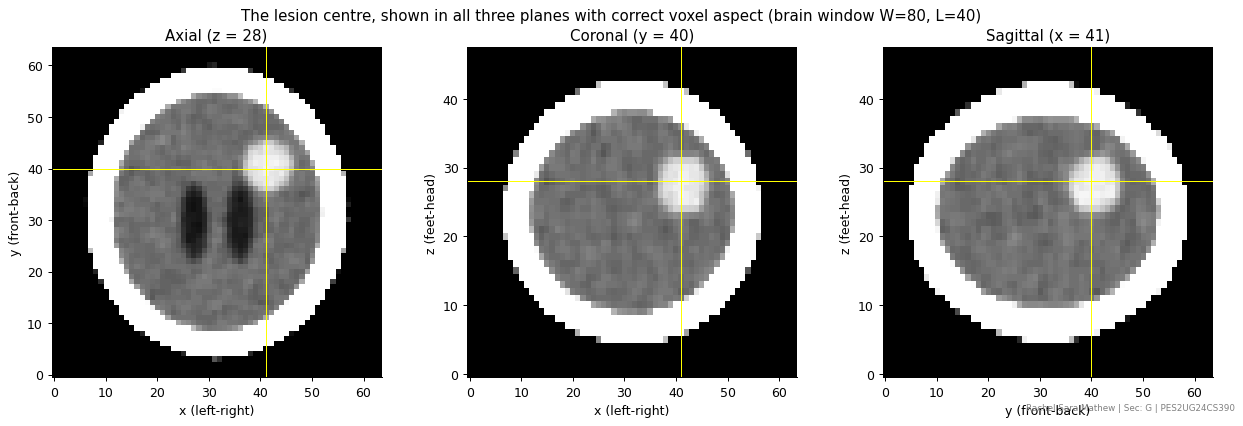

In [ ]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
solid = vol > 300
inside = ndimage.binary_fill_holes(solid) & ~solid
inside_er = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside_er

# TODO 2
lab, n = ndimage.label(candidates)
sizes = ndimage.sum(candidates, lab, range(1, n + 1))
lesion = lab == (1 + int(np.argmax(sizes)))
cz, cy, cx = [int(round(v)) for v in ndimage.center_of_mass(lesion)]
print(f"{n} candidate blobs, largest has {int(sizes.max())} voxels; centroid (z, y, x) = ({cz}, {cy}, {cx})")

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
views = [("Axial (z = %d)" % cz, vol[cz], 1.0, (cx, cy), "x (left-right)", "y (front-back)"),
         ("Coronal (y = %d)" % cy, vol[:, cy, :], ASPECT, (cx, cz), "x (left-right)", "z (feet-head)"),
         ("Sagittal (x = %d)" % cx, vol[:, :, cx], ASPECT, (cy, cz), "y (front-back)", "z (feet-head)")]
for ax, (title, sl, asp, (px, py), xl, yl) in zip(axes, views):
    ax.imshow(window(sl, 80, 40), cmap="gray", origin="lower", aspect=asp, vmin=0, vmax=1)
    ax.axvline(px, color="yellow", lw=0.8); ax.axhline(py, color="yellow", lw=0.8)
    ax.set(title=title, xlabel=xl, ylabel=yl)
fig.suptitle("The lesion centre, shown in all three planes with correct voxel aspect (brain window W=80, L=40)")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
tz, ty, tx = ndimage.center_of_mass(labels == 5)
err_mm = np.sqrt(((cz - tz) * SPACING[0]) ** 2 + ((cy - ty) * SPACING[1]) ** 2 + ((cx - tx) * SPACING[2]) ** 2)
print(f"Truth centroid ({tz:.1f}, {ty:.1f}, {tx:.1f}); my centroid is {err_mm:.1f} mm away")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_

The skull boundary is blurred by partial volume: voxels that straddle bone (about 700 HU) and brain (about 36 HU) average to intermediate values, so a thin shell under the skull falls inside 55-90 HU, exactly the range of the lesion. Because intensity ranges of different tissues overlap (Slide 28), thresholding alone cannot separate them. Eroding the brain mask three times removed this shell using spatial position, which the intensity cannot supply, leaving one large blob (431 voxels, centroid 2.9 mm from the ground truth).


## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

   threshold_HU  voxels  volume_mL      dice
0            45     535     19.260  0.928929
1            50     464     16.704  0.993534
2            55     431     15.516  0.963128
3            60     350     12.600  0.859951
4            65     273      9.828  0.740841
5            70     170      6.120  0.536278
Report to the surgeon: 6.1 - 19.3 mL (ground truth 16.7 mL)


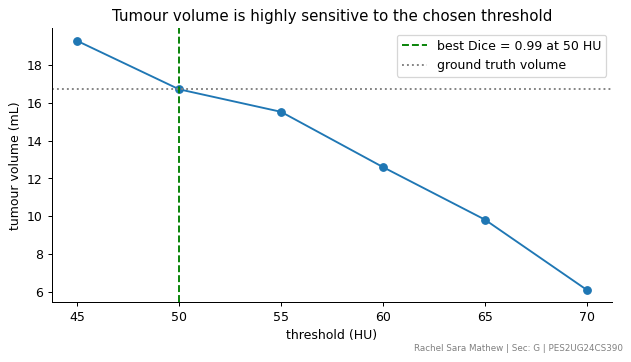

In [ ]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    lab_c, _ = ndimage.label(vol > c)
    region = lab_c == lab_c[cz, cy, cx]
    inter = (region & truth).sum()
    rows.append({"threshold_HU": c, "voxels": int(region.sum()),
                 "volume_mL": region.sum() * VOXEL_MM3 / 1000,
                 "dice": 2 * inter / (region.sum() + truth.sum())})

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold_HU, table.volume_mL, "o-")
best = table.loc[table.dice.idxmax()]
ax.axvline(best.threshold_HU, color="green", ls="--", label=f"best Dice = {best.dice:.2f} at {best.threshold_HU:.0f} HU")
ax.axhline(truth.sum() * VOXEL_MM3 / 1000, color="gray", ls=":", label="ground truth volume")
ax.set(xlabel="threshold (HU)", ylabel="tumour volume (mL)", title="Tumour volume is highly sensitive to the chosen threshold")
ax.legend(); plt.tight_layout(); plt.show()

# TODO 4
print(f"Report to the surgeon: {table.volume_mL.min():.1f} - {table.volume_mL.max():.1f} mL (ground truth {truth.sum() * VOXEL_MM3 / 1000:.1f} mL)")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

Volume changes a lot with c: 19.3 mL at 45 HU down to 6.1 mL at 70 HU, a threefold difference, with the best Dice (0.99) at 50 HU giving 16.7 mL. Without a label I would put c about half way between the surrounding brain (about 36 HU) and the lesion plateau (about 68 HU), check the contour on all three planes with an overlay, and report a range, not one number. To show uncertainty I would draw several nested contours (e.g. 45, 55, 65 HU) over the slices, or a volume-versus-threshold plot with the plausible band shaded, so the surgeon sees how much the boundary moves.


## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

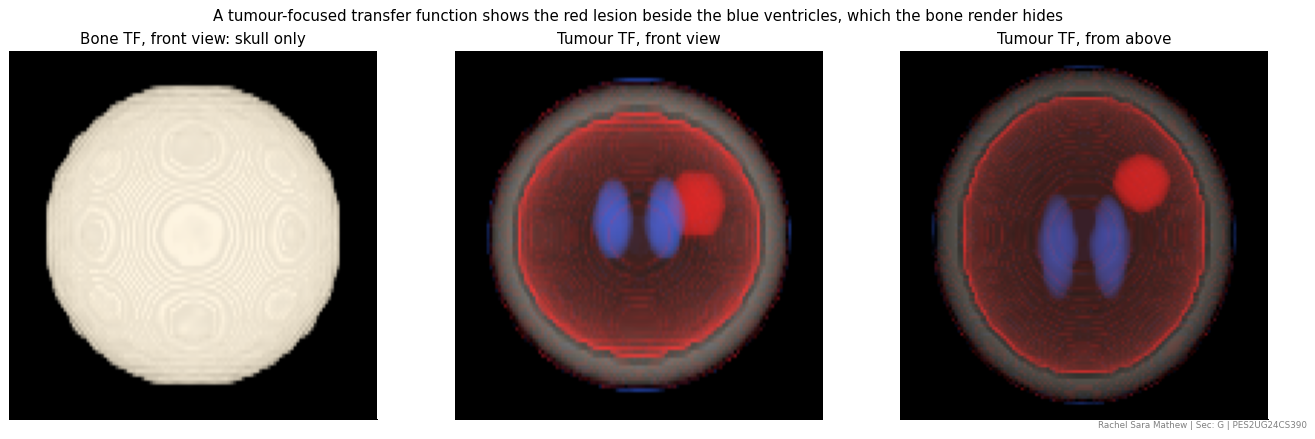

In [ ]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0), (-50, (0, 0, 0), 0.0),            # air / fat / scalp: transparent
    (0, (0.2, 0.4, 1), 0.0), (5, (0.2, 0.4, 1), 0.04),         # CSF: faint blue
    (20, (0.2, 0.4, 1), 0.04), (28, (0.2, 0.4, 1), 0.0),
    (45, (1, 0, 0), 0.0), (55, (1, 0.1, 0.1), 0.07),           # tumour: red, moderately opaque per sample
    (85, (1, 0.1, 0.1), 0.07), (100, (1, 0.1, 0.1), 0.0),
    (300, (1, 1, 1), 0.0), (400, (1, 0.95, 0.85), 0.01), (1500, (1, 1, 1), 0.01),   # bone: ghost only
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
C, A = render(vol, bone_tf, axis=1)
axes[0].imshow(np.clip(C, 0, 1), origin="lower", aspect=ASPECT); axes[0].set_title("Bone TF, front view: skull only")
C, A = render(vol, tumour_tf, axis=1)
axes[1].imshow(np.clip(C, 0, 1), origin="lower", aspect=ASPECT); axes[1].set_title("Tumour TF, front view")
C, A = render(vol, tumour_tf, axis=0)
axes[2].imshow(np.clip(C, 0, 1), origin="lower"); axes[2].set_title("Tumour TF, from above")
for a in axes: a.set_facecolor("black"); a.set_xticks([]); a.set_yticks([])

# TODO 4: suptitle
fig.suptitle("A tumour-focused transfer function shows the red lesion beside the blue ventricles, which the bone render hides")
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

The red rim comes from the overlap of intensity ranges and partial volume (Slide 28): voxels at the brain-skull boundary have the same HU values as the tumour, and a transfer function maps only intensity to colour and opacity, so it cannot tell them apart. Segmentation or masking (Slides 31-32), such as keeping only the connected component inside the eroded brain mask, or clipping away the outer shell, would remove it, because it uses connectivity and position and not just the value of one voxel.


## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

The lesion lies near the centre of the brain at voxel (z, y, x) = (28, 40, 41), and its volume is roughly 6-19 mL depending on the threshold, most plausibly about 15-17 mL at 50-55 HU. I would open with the segmentation overlay on the three-plane MPR slices, because slicing exposes internal structure without occlusion and the segmentation enables measurement with the threshold range shown. The 3-D render is good for context (red lesion next to the blue ventricles) but has a limitation: opacity accumulates along each ray, so the picture depends on the transfer function chosen and a faint rim or overlapping tissue can mislead, and depth cannot be judged from one view.
